# 18 - Discriminant et ramification : le critère de Dedekind

Le [carnet 17](17-chebotarev-frobenius-types-cycles.ipynb) a compté les types de décomposition de $x^3 - 2$ sur tous les premiers — **sauf 2 et 3**, écartés d'un mot : « elles divisent le discriminant ». Ce carnet tient la promesse : un seul entier, $\mathrm{disc}(f)$, prédit exactement quels premiers ramifient, avec quelles multiplicités, et pourquoi tous les autres ne ramifient pas. C'est le **critère de Dedekind**, tel que Serre l'expose au chapitre III de ses *Corps locaux* (1962) : le discriminant concentre toute la ramification du corps.

Le fil : (1) calculer $\mathrm{disc}(x^3-2) = -108$ par le résultant de Sylvester, à la main ; (2) prouver mécaniquement « racine multiple mod $p$ $\Leftrightarrow$ $p$ divise $\mathrm{disc}$ » ; (3) lire la décomposition de $p$ avec multiplicités — le tableau du carnet 17 augmenté de la colonne $e$ ; (4) voir la ramification *dans les idéaux* : $(2) = (\alpha)^3$ et $(3) = (\alpha+1)^3$ ; (5) un contraste honnête avec $x^2-5$, où $\mathrm{disc}(f)$ n'est pas $\mathrm{disc}(K)$. Puis trois exemples guidés et trois exercices.

## 1. Le discriminant, produit des différences

Pour $f$ unitaire de degré $n$ et de racines complexes $\alpha_1, \dots, \alpha_n$,

$$\mathrm{disc}(f) = \prod_{i < j} (\alpha_i - \alpha_j)^2 = (-1)^{n(n-1)/2}\, \mathrm{Res}(f, f'),$$

où $\mathrm{Res}(f, f')$ est le **résultant** de $f$ et de sa dérivée — le déterminant de la matrice de Sylvester $(m+n) \times (m+n)$. Pour le trinôme unitaire $x^3 + px + q$, la formule fermée $\mathrm{disc} = -4p^3 - 27q^2$ est célèbre ; nous la croisons avec le déterminant exact (algorithme de Bareiss, aucune approximation) comme contrôle d'identité.

In [1]:
import math


def premiers(n):
    """Crible d'Eratosthene : liste des premiers <= n."""
    crible = bytearray(b"\x01") * (n + 1)
    crible[0] = crible[1] = 0
    for i in range(2, math.isqrt(n) + 1):
        if crible[i]:
            for k in range(i * i, n + 1, i):
                crible[k] = 0
    return [i for i in range(2, n + 1) if crible[i]]


def _det_bareiss(mat):
    """Determinant exact d'une matrice carree a coefficients entiers."""
    M = [ligne[:] for ligne in mat]
    n, signe, prev = len(M), 1, 1
    for k in range(n - 1):
        if M[k][k] == 0:
            piv = next((i for i in range(k + 1, n) if M[i][k] != 0), None)
            if piv is None:
                return 0
            M[k], M[piv] = M[piv], M[k]
            signe = -signe
        for i in range(k + 1, n):
            for j in range(k + 1, n):
                M[i][j] = (M[i][j] * M[k][k] - M[i][k] * M[k][j]) // prev
        prev = M[k][k]
    return signe * M[n - 1][n - 1]


def resultant(a, b):
    """Res(a, b) : determinant de Sylvester (a, b listes d'entiers, indice = degre)."""
    m, n = len(a) - 1, len(b) - 1
    S = [[0] * (m + n) for _ in range(m + n)]
    for i in range(n):
        for j in range(m + 1):
            S[i][i + m - j] = a[j]
    for i in range(m):
        for j in range(n + 1):
            S[n + i][i + n - j] = b[j]
    return _det_bareiss(S)


def discr(f):
    """Discriminant d'un polynome unitaire : (-1)^(n(n-1)/2) * Res(f, f')."""
    n = len(f) - 1
    dp = [j * f[j] for j in range(1, len(f))]
    while dp and dp[-1] == 0:
        dp.pop()
    signe = -1 if (n * (n - 1) // 2) % 2 else 1
    return signe * resultant(f, dp)


def factorise(n):
    """Decomposition en facteurs premiers : liste croissante de (p, e)."""
    out, t = [], 2
    while t * t <= abs(n):
        if n % t == 0:
            e = 0
            while n % t == 0:
                n //= t
                e += 1
            out.append((t, e))
        t += 1
    if abs(n) > 1:
        out.append((abs(n), 1))
    return out


def _strip(a):
    """Supprime les zeros de plus haut degre."""
    while len(a) > 1 and a[-1] == 0:
        a.pop()
    return a


def ppmul(a, b):
    """Produit de deux polynomes (listes d'entiers, indice = degre)."""
    out = [0] * (len(a) + len(b) - 1)
    for i, x in enumerate(a):
        for j, y in enumerate(b):
            out[i + j] += x * y
    return out


def pdivmod(a, b, p):
    """Division euclidienne dans F_p[X] : renvoie (quotient, reste)."""
    a = _strip([c % p for c in a])
    b = _strip([c % p for c in b])
    if len(b) == 1:
        return _strip([c * pow(b[0], -1, p) % p for c in a]), [0]
    q = [0] * (len(a) - len(b) + 1)
    inv = pow(b[-1], -1, p)
    while len(a) >= len(b) and any(a):
        dec = len(a) - len(b)
        c = a[-1] * inv % p
        q[dec] = c
        for j in range(len(b)):
            a[dec + j] = (a[dec + j] - c * b[j]) % p
        _strip(a)
    return q, a


def ppgcd(a, b, p):
    """PGCD unitaire dans F_p[X] : [1] si premiers entre eux."""
    a = _strip([c % p for c in a])
    b = _strip([c % p for c in b])
    while any(b):
        _, r = pdivmod(a, b, p)
        a, b = b, r
    if not any(a):
        return [0]
    inv = pow(a[-1], -1, p)
    return [c * inv % p for c in a]


# Controle d'identite : Sylvester contre la formule fermee du trinome.
# Encodage indice = degre : x^3 + p x + q  ->  [q, p, 0, 1].
# Le temoin (2, 3) echouerait avec l'encodage de x^3 + p x^2 + q :
# disc(x^3 + 2x + 3) = -275, alors que disc(x^3 + 2x^2 + 3) = -339.
for p, q in [(0, -2), (-3, 1), (1, 1), (2, 3)]:
    assert discr([q, p, 0, 1]) == -(4 * p ** 3 + 27 * q ** 2)

f = [-2, 0, 0, 1]              # x^3 - 2
d = discr(f)
sig = "-" if d < 0 else ""
produit = " * ".join(f"{p}^{e}" for p, e in factorise(d))
print(f"disc(x^3 - 2) = {d} = {sig}{produit}")
print("Controle trinome -4p^3-27q^2 avec p=0, q=-2 :", -(4 * 0 ** 3 + 27 * (-2) ** 2))


disc(x^3 - 2) = -108 = -2^2 * 3^3
Controle trinome -4p^3-27q^2 avec p=0, q=-2 : -108


### Lecture du résultat

Le déterminant de Sylvester et la formule fermée donnent le **même entier** : $\mathrm{disc}(x^3-2) = -108 = -2^2 \cdot 3^3$. Deux diviseurs premiers, 2 et 3 — exactement les deux premiers que le carnet 17 avait exclus de ses comptages de densité. Ce n'est pas une coïncidence : c'est le théorème que ce carnet démontre mécaniquement.

## 2. Racine multiple mod $p$ $\Leftrightarrow$ $p$ divise le discriminant

$f$ a une racine multiple dans $\mathbb{F}_p$ si et seulement si $\gcd(f, f') \neq 1$ dans $\mathbb{F}_p[X]$ — le test est un simple Euclide mod $p$. Et comme $\mathrm{disc}(f) = \pm\, \mathrm{Res}(f, f')$, le résultant — entier qui s'annule exactement quand $f$ et $f'$ ont un facteur commun — dit que ce $\gcd$ dégénère **précisément pour les $p$ divisant $\mathrm{disc}(f)$**. Vérifions-le en balayant les premiers :

In [2]:
fp = [0, 0, 3]                 # derivee de x^3 - 2
avec_racine_multiple = [p for p in premiers(60) if ppgcd(f, fp, p) != [1]]
diviseurs = [p for p, _ in factorise(108)]
print("premiers p < 60 avec racine multiple mod p :", avec_racine_multiple)
print("diviseurs premiers de disc = -108          :", diviseurs)
assert avec_racine_multiple == diviseurs

premiers p < 60 avec racine multiple mod p : [2, 3]
diviseurs premiers de disc = -108          : [2, 3]


### Lecture du résultat

Les deux listes coïncident — et l'`assert` l'exige : $x^3-2$ a une racine multiple modulo $p$ **exactement quand** $p \in \{2, 3\}$, les diviseurs de $108$. La ramification n'est plus une exclusion ad hoc : c'est la donnée d'un entier.

## 3. Le critère de Dedekind : la décomposition avec multiplicités

> **Théorème (Dedekind).** Soit $f$ unitaire irréductible, $\alpha$ une racine, $K = \mathbb{Q}(\alpha)$, et supposons $p$ premier ne divisant pas l'indice $[\mathcal{O}_K : \mathbb{Z}[\alpha]]$. Si
> $$f \equiv \bar{g}_1^{e_1} \cdots \bar{g}_r^{e_r} \pmod{p}$$
> avec les $\bar{g}_i$ irréductibles **distincts** et unitaires, alors
> $$(p) = \mathfrak{p}_1^{e_1} \cdots \mathfrak{p}_r^{e_r}, \qquad \mathfrak{p}_i = (p,\, g_i(\alpha)),$$
> et le degré résiduel de $\mathfrak{p}_i$ est $\deg g_i$.

Pour $x^3 - 2$ : l'ordre $\mathbb{Z}[\sqrt[3]{2}]$ est **maximal** (le corps cubique pur $\mathbb{Q}(\sqrt[3]{2})$ a $\mathrm{disc}(K) = -27m^2 = -108$ exactement), donc le critère s'applique tel quel. Le tableau du carnet 17 se prolonge d'une colonne « multiplicité $e$ » :

In [3]:
def _eval(f, r, p):
    """Valeur de f en r dans F_p (schema de Horner)."""
    acc = 0
    for c in reversed(f):
        acc = (acc * r + c) % p
    return acc


def _divise_lineaire(f, r, p):
    """Divise f par (x - r) dans F_p[X] (f suppose avoir r pour racine)."""
    out, acc = [], 0
    for c in reversed(f):
        acc = (acc * r + c) % p
        out.append(acc)
    out.reverse()
    return out[1:]


def factorise_mod(f, p):
    """Facteurs irreductibles de f (degre <= 3) dans F_p[X]."""
    f = [c % p for c in f]
    facteurs = []
    for r in range(p):
        e = 0
        while len(f) > 1 and _eval(f, r, p) == 0:
            f = _divise_lineaire(f, r, p)
            e += 1
        if e:
            facteurs.append((1, e, r))
    if len(f) > 1:
        facteurs.append((len(f) - 1, 1, None))
    return facteurs


print(f"{'p':>3}  {'x^3 - 2 mod p':<26} {'e':<10} ramifie")
for p in [2, 3, 5, 7, 11, 13, 17, 23, 29, 31]:
    fac = factorise_mod([-2, 0, 0, 1], p)
    txt = " * ".join(
        (f"(x-{r})" + (f"^{e}" if e > 1 else "")) if deg == 1 else f"irr(deg {deg})"
        for deg, e, r in fac
    )
    mult = ",".join(str(e) for _, e, _ in fac)
    ram = "OUI" if any(e > 1 for _, e, _ in fac) else ""
    print(f"{p:>3}  {txt:<26} e=({mult}){'':<6}{ram}")

  p  x^3 - 2 mod p              e          ramifie
  2  (x-0)^3                    e=(3)      OUI
  3  (x-2)^3                    e=(3)      OUI
  5  (x-3) * irr(deg 2)         e=(1,1)      
  7  irr(deg 3)                 e=(1)      
 11  (x-7) * irr(deg 2)         e=(1,1)      
 13  irr(deg 3)                 e=(1)      
 17  (x-8) * irr(deg 2)         e=(1,1)      
 23  (x-16) * irr(deg 2)        e=(1,1)      
 29  (x-26) * irr(deg 2)        e=(1,1)      
 31  (x-4) * (x-7) * (x-20)     e=(1,1,1)      


### Lecture du résultat

Exactement deux lignes portent un exposant $e > 1$ : $p = 2$ ($x^3$, $e = 3$) et $p = 3$ ($(x-2)^3$, c'est-à-dire $(x+1)^3$ modulo 3). Pour elles, $(p) = \mathfrak{p}^3$ avec un **unique** idéal premier : c'est la **ramification totale**. Toutes les autres lignes ont $e = 1$ : premiers non ramifiés, dont les types $(1,1,1)$, $(2,1)$, $(3)$ — visibles ici en $p = 31$ totalement scindé, $p = 5$ de type $(2,1)$, $p = 7$ inertes — sont ceux que le carnet 17 a comptés en densités $1/6$, $1/2$, $1/3$.

## 4. Voir la ramification dans les idéaux : $(2) = (\alpha)^3$ et $(3) = (\alpha+1)^3$

Le critère est une égalité d'**idéaux** — et pour $x^3-2$, elle se voit sur des identités polynomiales brutes dans $\mathbb{Z}[\alpha]$, $\alpha = \sqrt[3]{2}$ :

- $\alpha^3 = 2$ donne $(\alpha)^3 = (\alpha^3) = (2)$ : ramification totale en 2, sans calcul ;
- pour 3, $(\alpha+1)^3 = 3(\alpha^2+\alpha+1)$ après réduction modulo $\alpha^3 - 2$, et $(\alpha - 1)(\alpha^2 + \alpha + 1) = \alpha^3 - 1 = 1$ : le facteur $\alpha^2+\alpha+1$ est une **unité**, donc $(\alpha+1)^3 = (3)$.

La norme $N(\alpha - c) = (-1)^n f(c)$ confirme que $N(\alpha) = 2$ et $N(\alpha+1) = 3$ : chaque générateur engendre un idéal premier au-dessus de son $p$.

In [4]:
def reduc(g, m):
    """Reduit g modulo x^3 - m : coefficients (degre <= 2) de g(alpha)."""
    g = list(g)
    while len(g) > 3:
        k = len(g) - 1
        g[k - 3] += m * g[k]
        g.pop()
    return g


def norme_alpha_moins(c, f):
    """N(alpha - c) = (-1)^n * f(c) pour f unitaire de degre n, racine alpha."""
    n = len(f) - 1
    return (-1) ** n * sum(co * c ** j for j, co in enumerate(f))


un_plus_x = ppmul([1, 1], ppmul([1, 1], [1, 1]))        # (x+1)^3
print("(x+1)^3 reduit mod (x^3-2) :", reduc(un_plus_x, 2), "= 3*(x^2+x+1)")
print("(x-1)*(x^2+x+1) reduit     :", reduc(ppmul([-1, 1], [1, 1, 1]), 2), "= 1 (unite)")
print("N(alpha)   =", norme_alpha_moins(0, [-2, 0, 0, 1]), "-> (alpha)^3   = (2)")
print("N(alpha+1) =", norme_alpha_moins(-1, [-2, 0, 0, 1]), "-> (alpha+1)^3 = (3)")

(x+1)^3 reduit mod (x^3-2) : [3, 3, 3] = 3*(x^2+x+1)
(x-1)*(x^2+x+1) reduit     : [1, 0, 0] = 1 (unite)
N(alpha)   = 2 -> (alpha)^3   = (2)
N(alpha+1) = 3 -> (alpha+1)^3 = (3)


### Lecture du résultat

Les deux identités tombent : $(\alpha+1)^3$ se réduit à $3(x^2+x+1)$, le facteur annexe est l'inverse de $\alpha - 1$, et les normes valent 2 et 3. La colonne $e = 3$ du tableau de la section 3 n'était pas une abstraction : **l'idéal $(3)$ est littéralement le cube de l'idéal principal $(\alpha+1)$**, et $(2)$ celui de $(\alpha)$. La ramification totale, vue de $\mathbb{Z}[\alpha]$, est une identité entre puissances d'idéaux principaux — portée par une unité explicite.

## 5. Le contraste quadratique : quand $\mathrm{disc}(f)$ n'est pas $\mathrm{disc}(K)$

Pour $f = x^2 - 5$ : $\mathrm{disc}(f) = 20 = 2^2 \cdot 5$, et l'Euclide mod $p$ détecte une racine double en $p = 2$ et $p = 5$. Mais le corps $K = \mathbb{Q}(\sqrt{5})$ a pour discriminant **fondamental** $\mathrm{disc}(K) = 5$ (car $5 \equiv 1 \bmod 4$, l'anneau des entiers est $\mathbb{Z}[\frac{1+\sqrt{5}}{2}]$ — le nombre d'or, déjà rencontré au carnet 11). L'écart est l'indice $[\mathcal{O}_K : \mathbb{Z}[\sqrt{5}]] = 2$, et $\mathrm{disc}(f) = \mathrm{disc}(K) \cdot \mathrm{indice}^2$. La « ramification en 2 » de $x^2-5$ est un artefact de l'ordre non maximal $\mathbb{Z}[\sqrt{5}]$ : dans $K$, seul 5 ramifie. Le critère de la section 3 garde sa forme exacte à condition de lire $\mathrm{disc}(K)$ — ou de travailler dans un ordre maximal, comme c'était le cas pour $x^3-2$.

In [5]:
g = [-5, 0, 1]                 # x^2 - 5
gp = [0, 2]                    # derivee 2x
ram_f = [p for p in premiers(50) if ppgcd(g, gp, p) != [1]]
print("premiers avec racine multiple pour x^2-5 (p < 50) :", ram_f)
print("disc(x^2-5) =", discr(g), "=", " * ".join(f"{p}^{e}" for p, e in factorise(discr(g))))
d = 5
disc_k = d if d % 4 == 1 else 4 * d
print("disc(Q(sqrt(5))) =", disc_k, "(5 = 1 mod 4, ordre maximal Z[(1+sqrt(5))/2])")
print("indice^2 = disc(f)/disc(K) =", discr(g) // disc_k, "-> indice =", round(math.sqrt(discr(g) // disc_k)))

premiers avec racine multiple pour x^2-5 (p < 50) : [2, 5]
disc(x^2-5) = 20 = 2^2 * 5^1
disc(Q(sqrt(5))) = 5 (5 = 1 mod 4, ordre maximal Z[(1+sqrt(5))/2])
indice^2 = disc(f)/disc(K) = 4 -> indice = 2


### Lecture du résultat

Deux lectures cette fois : l'instrument « racine multiple mod $p$ » voit $\{2, 5\}$ — les diviseurs de $20$ — mais le discriminant fondamental du corps est $5$. L'indice 2 sépare les deux : $x^2-5$ **n'est pas** une équation canonique pour $\mathbb{Q}(\sqrt{5})$, et le critère de Dedekind exact s'énonce sur $\mathrm{disc}(K)$. Pour $x^3 - 2$ aucune précaution de ce type n'était nécessaire : $\mathbb{Z}[\sqrt[3]{2}]$ est l'anneau des entiers tout rond (corps cubique pur, $m \not\equiv \pm 1 \bmod 9$).

## 6. Le théorème de Dedekind : la ramification est finie

> **Théorème (Dedekind).** Un premier $p$ ramifie dans $K$ si et seulement si $p$ divise $\mathrm{disc}(K)$.

Conséquence immédiate : un corps de nombres n'a qu'un **nombre fini** de premiers ramifiés — les diviseurs d'un seul entier. Sur $x^3-2$ : deux premiers ramifiés sur l'infinité des premiers, et la figure ci-dessous le montre — le compteur de ramifiés s'arrête à 2 pendant que $\pi(p)$ grimpe. C'est la signature arithmétique que les fonctions $L$ du carnet 16 traduisent en facteurs eulériens dégénérés : le conducteur d'une fonction $L$ est fait exactement de ces premiers-là.

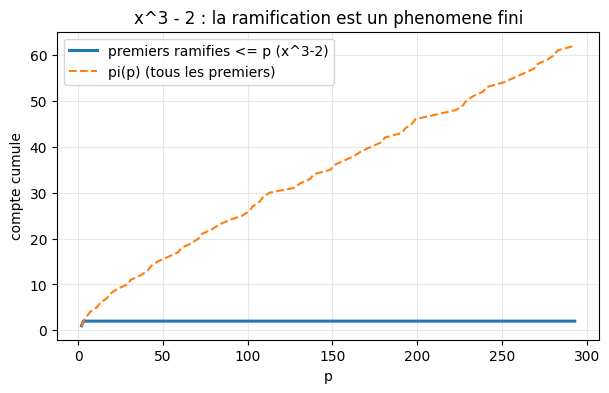

In [6]:
import matplotlib.pyplot as plt

tous = premiers(300)
ramifies = [p for p in tous if ppgcd([-2, 0, 0, 1], [0, 0, 3], p) != [1]]
cumul, vu = [], 0
for p in tous:
    vu += p in ramifies
    cumul.append(vu)

plt.figure(figsize=(7, 4))
plt.plot(tous, cumul, lw=2.2, label="premiers ramifies <= p (x^3-2)")
plt.plot(tous, range(1, len(tous) + 1), "--", lw=1.5, label="pi(p) (tous les premiers)")
plt.xlabel("p")
plt.ylabel("compte cumule")
plt.title("x^3 - 2 : la ramification est un phenomene fini")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Lecture du résultat

La courbe pleine s'aplatit à 2 dès $p = 3$ ; la courbe en pointillés croît sans borne ($\pi(300) = 62$). Deux ramifiés contre l'infinité des premiers inertes ou scindés : la ramification est une **exception finie**, la décomposition non ramifiée est la règle — et c'est sur cette règle que Chebotarev énonce ses densités. Le discriminant est l'œil du cyclone : nul en dehors de ses diviseurs.

## 7. Exemples guidés résolus et exercices

Trois **exemples guidés résolus** (solutions complètes exécutées), puis trois **exercices à compléter** (stub exécutable, cible annoncée). L'instrument reste le même : résultant et discriminant exacts, Euclide mod $p$, factorisation à multiplicités.

**Exemple guidé 1 — $x^3 - 3x + 1$ : prédire puis constater.** La formule du trinôme annonce $\mathrm{disc} = -4(-3)^3 - 27 = 81 = 3^4$ ; un seul premier ramifié, 3. Le critère prédit la ramification totale $(3) = \mathfrak{p}^3$ ; vérifions la racine triple modulo 3.

In [7]:
h = [1, -3, 0, 1]              # x^3 - 3x + 1
d = discr(h)
print("disc(x^3-3x+1) =", d, "=", " * ".join(f"{p}^{e}" for p, e in factorise(d)))
print("formule -4p^3-27q^2   :", -(4 * (-3) ** 3) - 27 * 1 ** 2)
mesure = [p for p in premiers(50) if ppgcd(h, [-3, 0, 3], p) != [1]]
print("racine multiple mod p :", mesure, "(p < 50)")
print("x^3-3x+1 mod 3        :", factorise_mod(h, 3))

disc(x^3-3x+1) = 81 = 3^4
formule -4p^3-27q^2   : 81
racine multiple mod p : [3] (p < 50)
x^3-3x+1 mod 3        : [(1, 3, 2)]


**Exercice 1 (à compléter) — $x^3 + x + 1$ : le discriminant premier.** Cible : $\mathrm{disc} = -31$, donc un unique premier ramifié, 31 — un discriminant premier, rien à factoriser. Compléter le stub.

In [8]:
print("A completer : disc(x^3+x+1) par la formule du trinome, la liste des premiers")
print("ramifies attendus ({31}), puis la verification : racine multiple mod 31.")


def ex1_discriminant():
    """Renvoie (disc(x^3+x+1), liste des premiers qui le divisent)."""
    # TODO etudiant
    # Etape 1 : appliquer la formule -4p^3-27q^2 avec p = 1, q = 1.
    # Etape 2 : factoriser le resultat avec factorise().
    # Etape 3 : verifier avec ppgcd([1, 0, 1, 1], [0, 0, 3], 31).
    return None  # TODO etudiant

A completer : disc(x^3+x+1) par la formule du trinome, la liste des premiers
ramifies attendus ({31}), puis la verification : racine multiple mod 31.


**Exemple guidé 2 — $x^3 - 3$ : la ramification totale en acte, et 2 qui ne ramifie pas.** $\mathrm{disc}(x^3-3) = -243 = -3^5$, et $(\alpha)^3 = (\alpha^3) = (3)$ littéralement. Le premier 2, lui, ne divise pas 243 : sa décomposition doit être non ramifiée — type $(2,1)$, une racine et un irréductible quadratique.

In [9]:
h = [-3, 0, 0, 1]              # x^3 - 3
d = discr(h)
sig = "-" if d < 0 else ""
print("disc(x^3-3) =", d, "=", sig + " * ".join(f"{p}^{e}" for p, e in factorise(d)))
print("N(alpha) =", norme_alpha_moins(0, h), "-> (alpha)^3 = (3), ramification totale")
print("x^3-3 mod 2 :", factorise_mod(h, 2), "type (2,1), non ramifie")

disc(x^3-3) = -243 = -3^5
N(alpha) = 3 -> (alpha)^3 = (3), ramification totale
x^3-3 mod 2 : [(1, 1, 1), (2, 1, None)] type (2,1), non ramifie


**Exercice 2 (à compléter) — $x^2 + 1$ : le discriminant réduit à $-4$.** Cible : seul 2 ramifie, et $x^2+1 \equiv (x+1)^2 \bmod 2$ — la ramification minimale des corps quadratiques imaginaires du carnet 11. Compléter le stub.

In [10]:
print("A completer : les premiers p < 30 ou x^2+1 a une racine multiple")
print("(attendu : [2], seul diviseur de disc = -4).")


def ex2_ramifies_x2_plus_1():
    """Renvoie la liste des premiers p ou x^2+1 a une racine multiple mod p."""
    # TODO etudiant
    # Etape 1 : balayer premiers(30) avec ppgcd([1, 0, 1], [0, 2], p).
    # Etape 2 : garder les p ou le pgcd n'est pas [1].
    # Etape 3 : confronter aux diviseurs de disc(x^2+1) = -4.
    return None  # TODO etudiant

A completer : les premiers p < 30 ou x^2+1 a une racine multiple
(attendu : [2], seul diviseur de disc = -4).


**Exemple guidé 3 — $x^2 - x - 1$ : le nombre d'or, ramifié en 5 seulement.** Ici $\mathbb{Z}[\alpha] = \mathcal{O}_K$ (l'équation est canonique), $\mathrm{disc} = 5$ : un seul ramifié, et la racine double est en $x = 3$ modulo 5.

In [11]:
h = [-1, -1, 1]                # x^2 - x - 1
print("disc(x^2-x-1) =", discr(h), "-> un seul premier ramifie : 5")
print("x^2-x-1 mod 5 :", factorise_mod(h, 5))

disc(x^2-x-1) = 5 -> un seul premier ramifie : 5
x^2-x-1 mod 5 : [(1, 2, 3)]


**Exercice 3 (à compléter) — $\Phi_3 = x^2+x+1$ : le conducteur cyclotomique.** Cible : $\mathrm{disc}(\Phi_3) = -3$, seul premier ramifié du troisième corps cyclotomique $\mathbb{Q}(\zeta_3)$ — celui-là même dont les ordres ont fait les densités de Dirichlet au carnet 17. Vérifier : $\Phi_3 \equiv (x-1)^2 \bmod 3$. Compléter le stub.

In [12]:
print("A completer : la factorisation de Phi_3 = x^2+x+1 dans F_3[X]")
print("(attendu : racine double en 1, multiplicite 2, donc e = 2 en p = 3).")


def ex3_phi3_mod_3():
    """Renvoie la factorisation de Phi_3 = x^2+x+1 dans F_3[X]."""
    # TODO etudiant
    # Etape 1 : construire la liste de coefficients de x^2+x+1.
    # Etape 2 : appeler factorise_mod(..., 3).
    # Etape 3 : interpreter : quelle racine, quelle multiplicite ?
    return None  # TODO etudiant

A completer : la factorisation de Phi_3 = x^2+x+1 dans F_3[X]
(attendu : racine double en 1, multiplicite 2, donc e = 2 en p = 3).


## Conclusion

D'un entier, $-108$, tombent trois lectures : quels premiers ramifient (2 et 3, diviseurs du discriminant), comment ils ramifient ($e = 3$, totalement, idéaux principaux $(\alpha)$ et $(\alpha+1)$), et pourquoi tous les autres portent les types que Chebotarev distribue. Le critère de Dedekind est le pont : le tableau du [carnet 17](17-chebotarev-frobenius-types-cycles.ipynb) augmenté de la colonne $e$, le fil des fonctions $L$ du [carnet 16](16-fonctions-l-dirichlet-progression-premiers.ipynb) dont le conducteur est fait des premiers ramifiés, et l'avertissement du $x^2-5$ : $\mathrm{disc}(f)$ n'est $\mathrm{disc}(K)$ que dans un ordre maximal. Le versant preuves existe dans Mathlib (`Polynomial.discr`) — le diptyque calcul/preuve de la série est au [carnet 08](08-serre-dans-mathlib-Lean.ipynb).